In [1]:
import pandas as pd
data=pd.read_csv("SwiftCart_Cleaned_Dataset.csv")
data["date"] = pd.to_datetime(data["date"], errors="coerce")
data['ship_postal_code'] = data['ship_postal_code'].astype('Int64').astype('string')

## Visualization for swift cart dataset analysis

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

**1. Numerical data visualizations**

**A. Histogram — Amount distribution**

**Shows how recorded transaction amounts are distributed.**

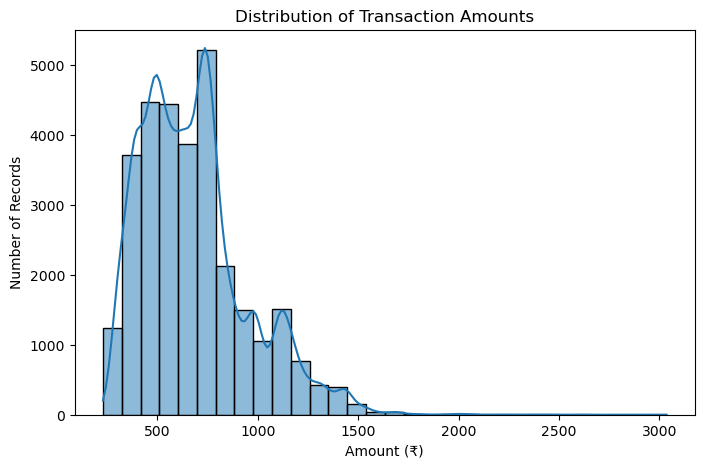

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="amount", bins=30, kde=True)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Amount (₹)")
plt.ylabel("Number of Records")
plt.show()

**Observation: Most transaction amounts fall between approximately ₹300 and ₹1,200, with very few above ₹1,500.**

**Interpretation: Most recorded transactions fall within a lower-to-middle spending range.**

**Business Insight: Test product bundles and add-on offers within common spending ranges to encourage customers to increase their purchase value.**

In [ ]:
B. Box plot — Amount by status
Identifies differences in amount distributions and potential outliers across order statuses.

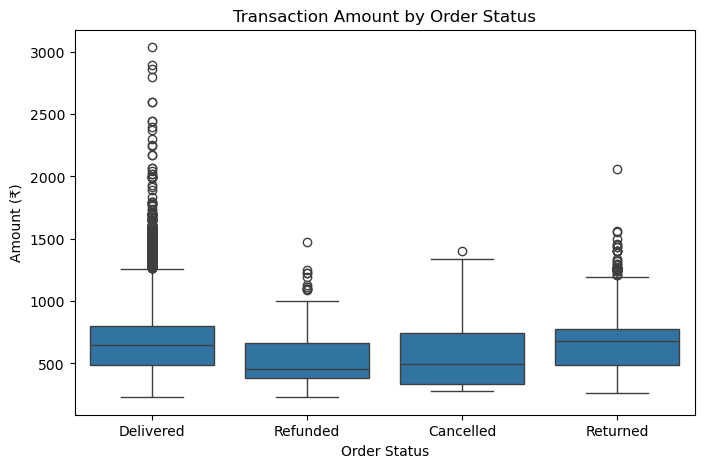

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="status", y="amount")
plt.title("Transaction Amount by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Amount (₹)")
plt.show()

**Observation: Delivered orders have the most high-value outliers, while Refunded orders have the lowest median transaction amount.**

**Interpretation: Returned and Delivered orders generally have higher median transaction amounts than Refunded orders.**

**Business Insight: Investigate high-value Returned orders to identify potential revenue loss and reduce return-related financial risks.**

**C. Scatter plot — Quantity vs amount**

**Examines the relationship between quantity and recorded amount.**

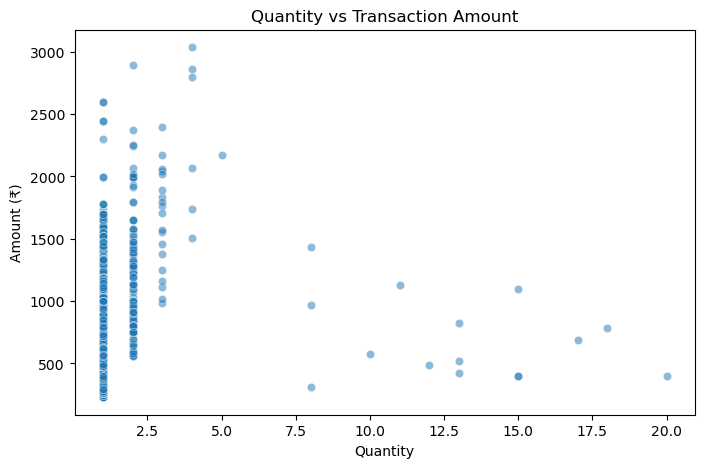

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="quantity", y="amount", alpha=0.5)
plt.title("Quantity vs Transaction Amount")
plt.xlabel("Quantity")
plt.ylabel("Amount (₹)")
plt.show()

**Observation: Most records have quantities between 1 and 4, and amounts vary widely. The correlation is only 0.054.**

**Interpretation: Higher quantities do not consistently correspond to higher recorded amounts.**

**Business Insight: Create bundle offers based on product prices and category demand rather than assuming that customers buying more items will always spend more.**

## 2. Categorical data visualizations

**D. Count plot — Order status**
    
**Compares the number of records in each status.**

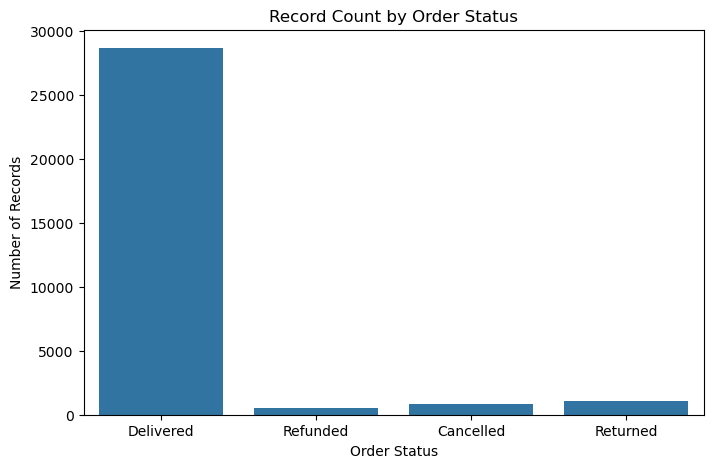

In [12]:
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="status")
plt.title("Record Count by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Records")
plt.show()

**Observation: Delivered records are highest at 28,641, followed by Returned (1,045), Cancelled (844), and Refunded (517).**

**Interpretation: Most records are delivered, but some transactions end in returns, cancellations, or refunds.**

**Business Insight: Analyze the reasons for returns and cancellations separately, then prioritize corrective actions for the most common causes to reduce unsuccessful transactions.**

**E. Bar chart — Category-wise recorded amount**
    
**Compares the total recorded amount across product categories.**

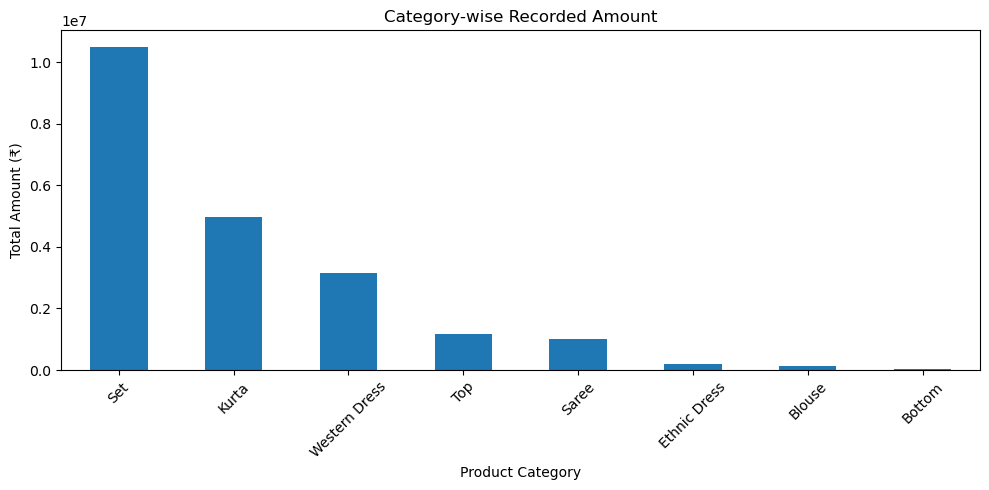

In [14]:
category_amount = data.groupby("category")["amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
category_amount.plot(kind="bar")
plt.title("Category-wise Recorded Amount")
plt.xlabel("Product Category")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation: Sets contribute approximately ₹10.51M, Kurtas ₹4.96M, and Western Dresses ₹3.15M. Bottom contributes the least.**

**Interpretation: Sets and Kurtas are the largest contributors to recorded sales value.**

**Business Insight: Prioritize stock replenishment for Sets and Kurtas. Test targeted promotions for Bottom before investing in additional inventory.**

## 3. Time-based visualization

**F. Line chart — Monthly recorded amount**

**Shows how recorded amounts change throughout the year.**

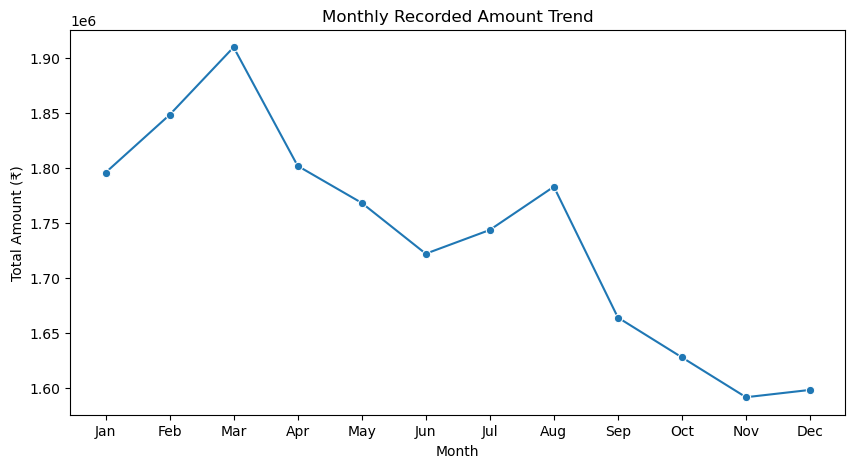

In [17]:
monthly_amount = data.groupby("month")["amount"].sum()

month_order = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_amount = monthly_amount.reindex(month_order)

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_amount.index, y=monthly_amount.values, marker="o")
plt.title("Monthly Recorded Amount Trend")
plt.xlabel("Month")
plt.ylabel("Total Amount (₹)")
plt.show()

**Observation: March has the highest recorded amount (₹1.91M), while November has the lowest (₹1.59M). Amounts decline from August through November.**

**Interpretation: Recorded sales value weakens during the later months, especially in November.**

**Business Insight: Plan targeted November campaigns and review March's successful products and promotions to identify strategies worth repeating.**

## 4. Relationship visualization

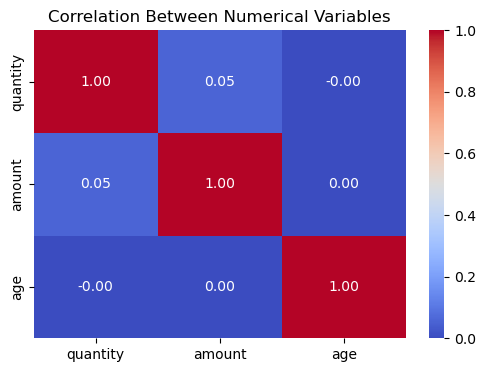

In [20]:
plt.figure(figsize=(6, 4))
correlation = data[["quantity", "amount", "age"]].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Variables")
plt.show()

**Observation: Quantity and amount have a correlation of approximately 0.05. Age has almost zero correlation with both.**

**Interpretation: Age and quantity have little linear relationship with recorded transaction amounts.**

**Business Insight: Base sales campaigns on customers' purchase history and product preferences rather than using age or quantity alone to predict spending.**

## 5. Distribution comparison

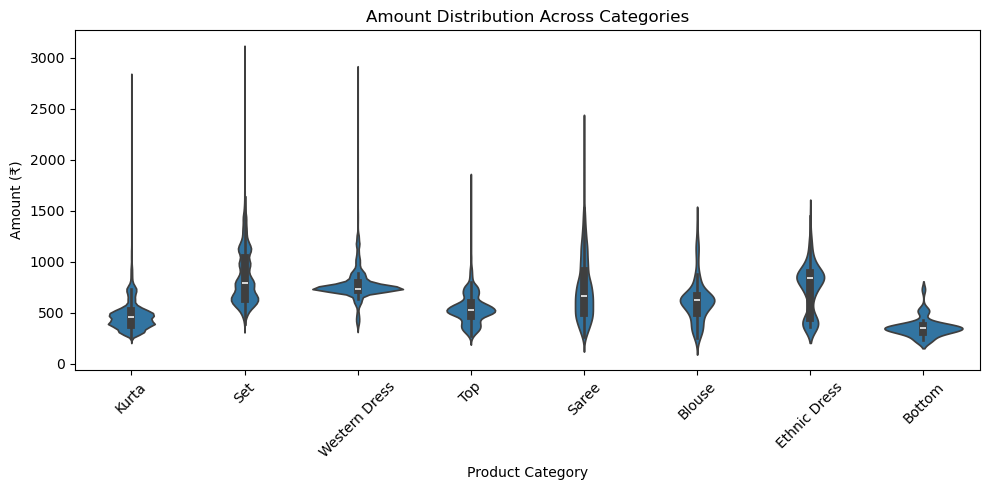

In [23]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=data, x="category", y="amount")
plt.title("Amount Distribution Across Categories")
plt.xlabel("Product Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation: Sets and Western Dresses show broad amount distributions. Bottom transactions are concentrated at lower amounts, while Kurtas also show some high-value records.**

**Interpretation: Transaction amounts vary across categories, with some categories showing greater variation than others.**

**Business Insight: Review the products and price points driving higher-value transactions in Sets and Western Dresses. Test targeted bundles for Bottom to encourage higher purchase values.**

In [3]:
data.columns

Index(['index', 'order_id', 'customer_id', 'gender', 'age', 'age_group',
       'date', 'month', 'status', 'channel', 'sku', 'category', 'size',
       'quantity', 'currency', 'amount', 'ship_city', 'ship_state',
       'ship_postal_code', 'ship_country', 'b2b'],
      dtype='object')